# SIT720 Task 6.2C - Classification Models
## Gallstone Disease Classification

**Student name:** Zenith Anthony Dabarera  
**Student ID:** s225534396  
**Unit:** SIT720 Machine Learning  

This notebook implements the current 6.2C brief: a stratified 70:30 train-test split, two classification models, cross-validation, hyperparameter optimisation, model diagnosis, class-imbalance assessment, untouched test-set evaluation, and an 80:20 robustness check.

> **GenAI acknowledgement:** ChatGPT was used to assist with planning, an initial code scaffold, debugging, and language editing. The numerical results in this notebook come from executing the code on the Gallstone dataset. The student should critically review the logic, outputs, and interpretations and be able to explain them during tutor follow-up.


## 1. Understanding the classification problem

**Problem.** Predict whether a patient has gallstone disease from non-imaging demographic, body-composition/bioimpedance and laboratory measurements.

**Inputs.** The UCI dataset contains 38 predictors including age, gender, comorbidities, height, weight, BMI, body water/fat/muscle measures, glucose, lipid profile, liver enzymes, creatinine, GFR, CRP, haemoglobin and vitamin D.

**Output.** `Gallstone Status` is binary. UCI codes **0 = gallstones present** and **1 = absent**. For clinically intuitive evaluation, this notebook creates `Gallstone_Present = 1` when the original status equals 0, so precision/recall refer to correctly detecting disease.

**Practical significance.** A model based on routinely available measurements could support risk screening and prioritisation for further clinical assessment. It is not a replacement for imaging or a clinician.

**Error consequences.** A false negative is clinically more concerning because a person with gallstones is labelled as low risk, which could delay follow-up. A false positive can lead to unnecessary concern or further testing. For that reason, recall for the disease-positive class is reported alongside accuracy, F1 and ROC-AUC.


In [1]:
# 0. Imports and settings
from pathlib import Path
import sys, subprocess, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, classification_report
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
warnings.filterwarnings('ignore')

OUTPUT_DIR = Path('sit720_6_2c_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
print('Output folder:', OUTPUT_DIR.resolve())


Output folder: /mnt/data/sit720_6_2c_outputs


## 2. Data exploration and preparation

In [2]:
# 2.1 Load the UCI Gallstone dataset
# Priority: local CSV -> official UCI API -> public raw mirror fallback.
local_candidates = [
    Path('dataset-uci.csv'),
    Path('gallstone.csv'),
    Path('/content/dataset-uci.csv'),
    Path('/mnt/data/dataset-uci.csv'),
]
local_file = next((p for p in local_candidates if p.exists()), None)

df = None
data_source = None

if local_file is not None:
    df = pd.read_csv(local_file, encoding='utf-8-sig')
    data_source = f'Local file: {local_file}'
else:
    try:
        try:
            from ucimlrepo import fetch_ucirepo
        except ImportError:
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ucimlrepo'])
            from ucimlrepo import fetch_ucirepo
        gallstone = fetch_ucirepo(id=1150)
        X_uci = gallstone.data.features.copy()
        y_uci = gallstone.data.targets.copy()
        df = pd.concat([y_uci.reset_index(drop=True), X_uci.reset_index(drop=True)], axis=1)
        data_source = 'Official UCI Machine Learning Repository via ucimlrepo (dataset 1150)'
    except Exception as e:
        print('UCI API load failed:', type(e).__name__, str(e)[:180])
        raw_url = ('https://raw.githubusercontent.com/krispybataa/'
                   'cmsc177-capstone-grp3/refs/heads/main/%28CSV%29dataset-uci.csv')
        df = pd.read_csv(raw_url, encoding='utf-8-sig')
        data_source = 'Public GitHub mirror of the UCI Gallstone CSV'

# Clean column names and remove any accidental duplicate columns.
df.columns = [str(c).replace('\ufeff','').strip() for c in df.columns]
df = df.loc[:, ~df.columns.duplicated()].copy()

print('Data source:', data_source)
print('Dataset shape:', df.shape)
display(df.head())


Data source: Local file: dataset-uci.csv
Dataset shape: (319, 39)


,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,Body Mass Index (BMI),Total Body Water (TBW),Extracellular Water (ECW),Intracellular Water (ICW),Extracellular Fluid/Total Body Water (ECF/TBW),Total Body Fat Ratio (TBFR) (%),Lean Mass (LM) (%),Body Protein Content (Protein) (%),Visceral Fat Rating (VFR),Bone Mass (BM),Muscle Mass (MM),Obesity (%),Total Fat Content (TFC),Visceral Fat Area (VFA),Visceral Muscle Area (VMA) (Kg),Glucose,Total Cholesterol (TC),Low Density Lipoprotein (LDL),High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D,Hepatic Fat Accumulation (HFA)
0,1,26,1,3,1,1,0,0,56.4889,45.1402,65.7097,54.4189,68.1390,57.6299,31.8492,62.9473,47.4283,43.8840,55.9190,73.1884,38.3689,45.3238,55.0624,69.8711,53.4377,64.6061,54.0964,63.6359,65.7390,47.1538,68.7075,56.3496,41.6500,38.9683,39.8479,55.9720,37.7921,62.5650,0
1,0,74,0,3,1,1,1,1,50.9287,46.9390,29.0347,63.8396,73.5700,23.3988,84.9654,47.5742,30.6388,50.3894,77.6617,53.6011,57.5070,63.0181,34.9234,56.9111,50.9896,41.6115,67.5817,46.8356,38.0128,47.2286,47.6175,54.3196,58.3031,48.2085,47.3869,43.4282,39.3973,52.0979,3
2,0,65,0,2,0,0,1,0,51.6559,42.6252,40.0595,59.9006,73.5500,56.8099,62.2917,39.9501,46.0461,19.9578,55.9059,45.6094,55.3536,26.2032,60.7793,80.2671,75.7157,51.6153,20.3112,43.4031,51.8024,46.4760,31.8758,44.3898,56.4828,59.5874,79.7190,64.3520,52.8459,41.4054,3
3,1,50,1,3,0,1,1,0,43.8750,41.2902,78.8442,78.7467,35.0296,68.4930,44.9882,67.0291,70.0457,38.6020,44.1966,61.3568,33.6754,41.8764,47.6297,52.6585,46.5480,40.2841,11.6348,74.1375,56.6782,33.2610,70.0605,53.4864,50.1215,63.3808,53.7682,49.0764,63.5613,39.3795,3
4,1,50,1,3,0,1,1,0,29.0284,60.4201,66.9103,38.5484,44.7160,46.6761,68.7353,61.6084,53.5601,64.7486,61.4928,63.0305,67.9523,80.6723,58.4079,86.7170,47.4260,55.9698,44.0106,58.4960,43.9965,82.2533,49.2642,67.8928,27.1011,69.1636,63.0399,75.7827,32.5106,56.1535,0


Rows: 319
Predictor columns: 38
Total columns including target: 39

Data types:


,dtype
Gallstone Status,int64
Age,int64
Gender,int64
Comorbidity,int64
Coronary Artery Disease (CAD),int64
Hypothyroidism,int64
Hyperlipidemia,int64
Diabetes Mellitus (DM),int64
Height,float64
Weight,float64



Total missing entries: 0


,missing_count
Gallstone Status,0
Age,0
Gender,0
Comorbidity,0
Coronary Artery Disease (CAD),0
Hypothyroidism,0
Hyperlipidemia,0
Diabetes Mellitus (DM),0
Height,0
Weight,0


Duplicate rows: 0

Original UCI target counts (0 = present, 1 = absent):


,count
Gallstone Status,
0,159
1,160


,count,percent
Absent (0),160,50.1567
Present (1),159,49.8433


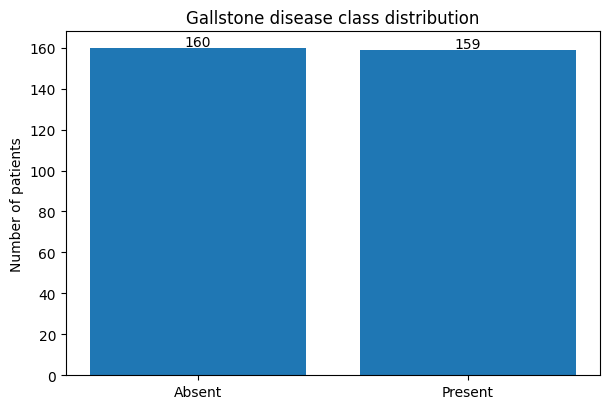

In [3]:
# 2.2 Data-quality assessment: dimensions, types, missing values, duplicates, target distribution
TARGET = 'Gallstone Status'
assert TARGET in df.columns, f"Expected target '{TARGET}' not found. Columns: {list(df.columns)}"

print('Rows:', df.shape[0])
print('Predictor columns:', df.shape[1] - 1)
print('Total columns including target:', df.shape[1])
print('\nData types:')
display(df.dtypes.to_frame('dtype'))

missing = df.isna().sum().sort_values(ascending=False)
print('\nTotal missing entries:', int(missing.sum()))
display(missing.to_frame('missing_count').head(15))
print('Duplicate rows:', int(df.duplicated().sum()))

print('\nOriginal UCI target counts (0 = present, 1 = absent):')
display(df[TARGET].value_counts(dropna=False).sort_index().to_frame('count'))

# Recode so positive class = disease present.
y = (pd.to_numeric(df[TARGET], errors='coerce') == 0).astype(int)
y.name = 'Gallstone_Present'
X = df.drop(columns=[TARGET]).copy()

class_table = pd.DataFrame({
    'count': y.value_counts().sort_index(),
    'percent': y.value_counts(normalize=True).sort_index() * 100
})
class_table.index = ['Absent (0)', 'Present (1)']
display(class_table)

fig, ax = plt.subplots(figsize=(6.2,4.2))
ax.bar(['Absent','Present'], class_table['count'])
ax.set_title('Gallstone disease class distribution')
ax.set_ylabel('Number of patients')
for i,v in enumerate(class_table['count']):
    ax.text(i, v+1, str(int(v)), ha='center')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'01_class_distribution.png', dpi=180, bbox_inches='tight')
plt.show()


In [4]:
# 2.3 Feature types and preprocessing decisions
# UCI metadata identifies these as categorical/binary/ordinal-coded features.
categorical_features = [
    'Gender',
    'Comorbidity',
    'Coronary Artery Disease (CAD)',
    'Hypothyroidism',
    'Hyperlipidemia',
    'Diabetes Mellitus (DM)',
    'Hepatic Fat Accumulation (HFA)'
]
categorical_features = [c for c in categorical_features if c in X.columns]
continuous_features = [c for c in X.columns if c not in categorical_features]

feature_type_table = pd.DataFrame({
    'feature': list(X.columns),
    'type': ['categorical/binary/ordinal' if c in categorical_features else 'continuous/integer' for c in X.columns]
})
print('Categorical/binary/ordinal features:', len(categorical_features))
print('Continuous/integer features:', len(continuous_features))
display(feature_type_table)
feature_type_table.to_csv(OUTPUT_DIR/'feature_types.csv', index=False)

# Robust preprocessing. The official dataset reports no missing values, so the imputers
# normally make no changes; they are kept to make the pipeline safe and leakage-free.
try:
    encoder = OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False)
except TypeError:  # scikit-learn < 1.2
    encoder = OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse=False)

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', encoder)
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipe, continuous_features),
    ('cat', cat_pipe, categorical_features)
], remainder='drop')

print('Preprocessing: median imputation + standardisation for continuous features;')
print('most-frequent imputation + one-hot encoding for categorical/ordinal-coded features.')
print('Because the source dataset is complete, imputation is a defensive step rather than a data alteration.')


Categorical/binary/ordinal features: 7
Continuous/integer features: 31


,feature,type
0,Age,continuous/integer
1,Gender,categorical/binary/ordinal
2,Comorbidity,categorical/binary/ordinal
3,Coronary Artery Disease (CAD),categorical/binary/ordinal
4,Hypothyroidism,categorical/binary/ordinal
5,Hyperlipidemia,categorical/binary/ordinal
6,Diabetes Mellitus (DM),categorical/binary/ordinal
7,Height,continuous/integer
8,Weight,continuous/integer
9,Body Mass Index (BMI),continuous/integer


Preprocessing: median imputation + standardisation for continuous features;
most-frequent imputation + one-hot encoding for categorical/ordinal-coded features.
Because the source dataset is complete, imputation is a defensive step rather than a data alteration.


Top absolute Pearson/point-biserial associations with disease status:


,correlation
Age,0.6360
Hepatic Fat Accumulation (HFA),0.1119
Aspartat Aminotransferaz (AST),0.1038
Coronary Artery Disease (CAD),0.0977
Hyperlipidemia,-0.0973
Glucose,-0.0746
Vitamin D,-0.0741
Hemoglobin (HGB),-0.0715
Muscle Mass (MM),-0.0674
Body Mass Index (BMI),-0.0633


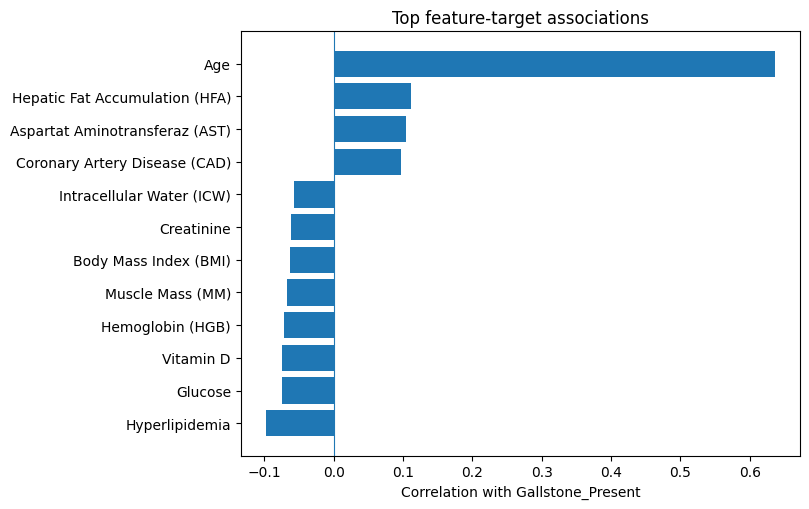


Highly correlated continuous-feature pairs (|r| >= 0.85):


,result
0,None at threshold 0.85


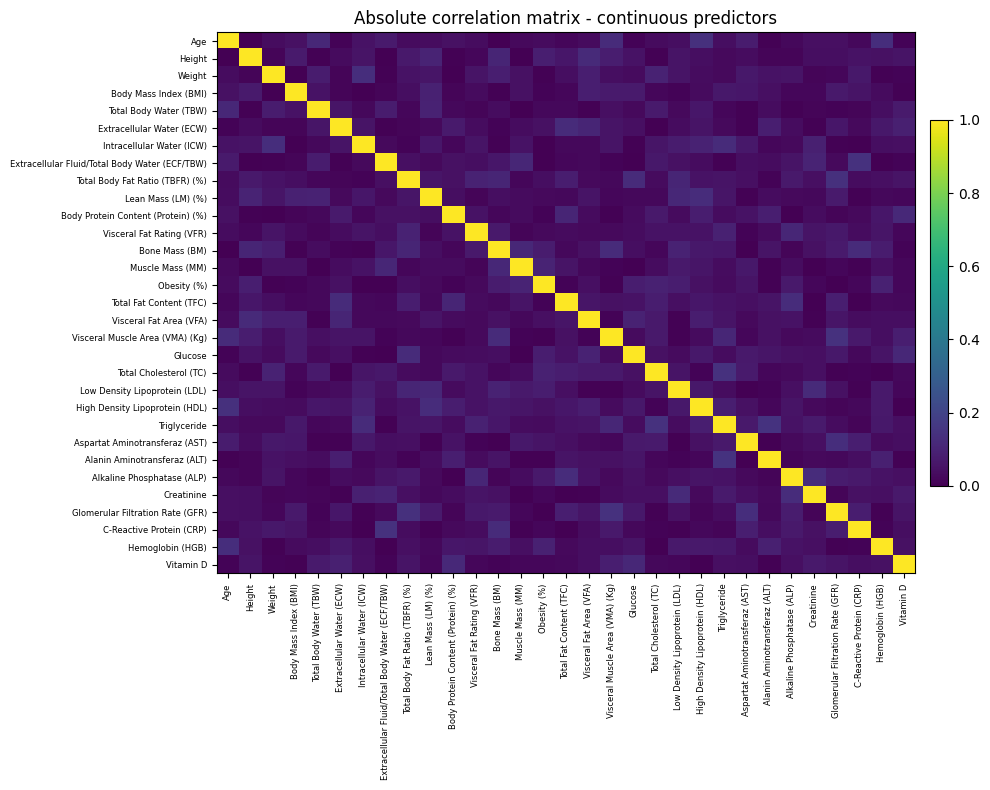

In [5]:
# 2.4 Exploratory relationships: target association and feature dependencies
# Convert all predictors to numeric for simple exploratory correlations (codes retained only for EDA).
X_num = X.apply(pd.to_numeric, errors='coerce')
eda = X_num.copy()
eda['Gallstone_Present'] = y.values

target_corr = eda.corr(numeric_only=True)['Gallstone_Present'].drop('Gallstone_Present').sort_values(key=np.abs, ascending=False)
print('Top absolute Pearson/point-biserial associations with disease status:')
display(target_corr.head(12).to_frame('correlation'))
target_corr.to_csv(OUTPUT_DIR/'target_correlations.csv', header=['correlation'])

fig, ax = plt.subplots(figsize=(8.2,5.2))
top = target_corr.head(12).sort_values()
ax.barh(top.index, top.values)
ax.axvline(0, linewidth=0.8)
ax.set_xlabel('Correlation with Gallstone_Present')
ax.set_title('Top feature-target associations')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'02_top_target_correlations.png', dpi=180, bbox_inches='tight')
plt.show()

# Highly correlated predictor pairs can be redundant.
corr = X_num[continuous_features].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_pairs = [(col, row, float(upper.loc[row,col]))
              for col in upper.columns for row in upper.index
              if pd.notna(upper.loc[row,col]) and upper.loc[row,col] >= 0.85]
high_corr_df = pd.DataFrame(high_pairs, columns=['feature_1','feature_2','abs_correlation']).sort_values('abs_correlation', ascending=False)
print('\nHighly correlated continuous-feature pairs (|r| >= 0.85):')
display(high_corr_df.head(20) if len(high_corr_df) else pd.DataFrame({'result':['None at threshold 0.85']}))
high_corr_df.to_csv(OUTPUT_DIR/'highly_correlated_pairs.csv', index=False)

# Heatmap without seaborn.
fig, ax = plt.subplots(figsize=(10,8))
im = ax.imshow(corr.values, aspect='auto', vmin=0, vmax=1)
ax.set_title('Absolute correlation matrix - continuous predictors')
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=6)
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index, fontsize=6)
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'03_continuous_correlation_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()


In [6]:
# 2.5 70:30 stratified split - test set remains untouched during tuning
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)
print('70:30 split')
print('Training shape:', X_train.shape, 'Test shape:', X_test.shape)
print('Training disease prevalence:', f'{y_train.mean():.3f}')
print('Test disease prevalence:', f'{y_test.mean():.3f}')


70:30 split
Training shape: (223, 38) Test shape: (96, 38)
Training disease prevalence: 0.498
Test disease prevalence: 0.500


## 3. Model development, validation and hyperparameter optimisation

Two deliberately different models are compared:

1. **Logistic Regression** - a regularised linear probabilistic classifier. It is computationally light and its coefficients can be interpreted, but it may underfit nonlinear interactions.
2. **Random Forest** - an ensemble of decision trees that can model nonlinearities and interactions with few distributional assumptions. It is less transparent, more computationally expensive and may overfit a small dataset if trees are too deep.

**Validation strategy.** Hyperparameters are selected using stratified 5-fold cross-validation on the training set only. The primary tuning metric is ROC-AUC because it evaluates ranking quality across thresholds; accuracy, balanced accuracy, precision, recall and F1 are also reported.


In [7]:
# 3.1 Pipelines and hyperparameter grids
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

log_pipe = Pipeline([
    ('preprocess', preprocessor),
    ('model', LogisticRegression(max_iter=5000, solver='liblinear', random_state=RANDOM_STATE))
])
log_grid = {
    'model__C': [0.1, 1, 10],
    'model__penalty': ['l1', 'l2']
}

rf_pipe = Pipeline([
    ('preprocess', preprocessor),
    ('model', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))
])
rf_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 6],
    'model__min_samples_leaf': [1, 3],
    'model__max_features': ['sqrt']
}

searches = {}
for name, pipe, grid in [
    ('Logistic Regression', log_pipe, log_grid),
    ('Random Forest', rf_pipe, rf_grid)
]:
    print(f'\nTuning {name} ...')
    start = time.perf_counter()
    gs = GridSearchCV(pipe, grid, cv=cv, scoring='roc_auc', n_jobs=-1, refit=True, return_train_score=True)
    gs.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    searches[name] = {'search': gs, 'tuning_seconds': elapsed}
    print('Best CV ROC-AUC:', round(gs.best_score_, 4))
    print('Best parameters:', gs.best_params_)
    print('Tuning time (s):', round(elapsed, 2))



Tuning Logistic Regression ...


Best CV ROC-AUC: 0.8768
Best parameters: {'model__C': 0.1, 'model__penalty': 'l1'}
Tuning time (s): 5.83

Tuning Random Forest ...


Best CV ROC-AUC: 0.8534
Best parameters: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 3, 'model__n_estimators': 200}
Tuning time (s): 4.1


,Mean train ROC-AUC,Mean validation ROC-AUC,Train-validation gap,Diagnosis,Tuning seconds
Model,,,,,
Logistic Regression,0.8908,0.8768,0.0140,generalising reasonably in cross-validation,5.8349
Random Forest,1.0000,0.8534,0.1466,possible overfitting,4.1040


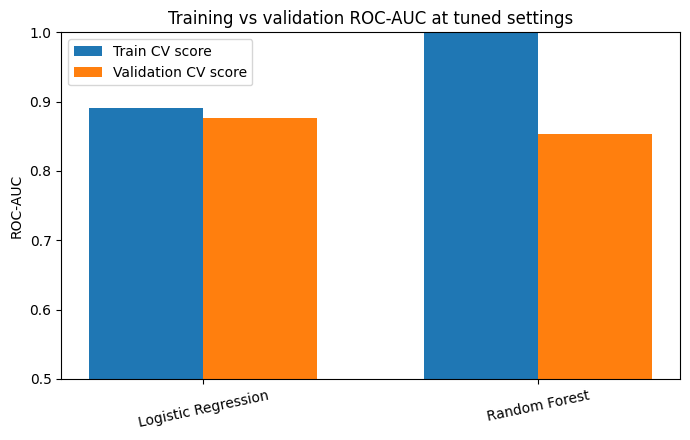

In [8]:
# 3.2 Cross-validation summary and model diagnosis
cv_rows=[]
for name, obj in searches.items():
    gs = obj['search']
    best_idx = gs.best_index_
    train_auc = gs.cv_results_['mean_train_score'][best_idx]
    val_auc = gs.cv_results_['mean_test_score'][best_idx]
    gap = train_auc - val_auc
    if val_auc < 0.65 and train_auc < 0.70:
        diagnosis = 'possible underfitting'
    elif gap > 0.10:
        diagnosis = 'possible overfitting'
    else:
        diagnosis = 'generalising reasonably in cross-validation'
    cv_rows.append({
        'Model': name,
        'Mean train ROC-AUC': train_auc,
        'Mean validation ROC-AUC': val_auc,
        'Train-validation gap': gap,
        'Diagnosis': diagnosis,
        'Tuning seconds': obj['tuning_seconds']
    })
cv_summary = pd.DataFrame(cv_rows).set_index('Model')
display(cv_summary)
cv_summary.to_csv(OUTPUT_DIR/'cv_model_summary.csv')

fig, ax = plt.subplots(figsize=(7,4.5))
x=np.arange(len(cv_summary))
w=0.34
ax.bar(x-w/2, cv_summary['Mean train ROC-AUC'], width=w, label='Train CV score')
ax.bar(x+w/2, cv_summary['Mean validation ROC-AUC'], width=w, label='Validation CV score')
ax.set_xticks(x)
ax.set_xticklabels(cv_summary.index, rotation=12)
ax.set_ylim(0.5,1.0)
ax.set_ylabel('ROC-AUC')
ax.set_title('Training vs validation ROC-AUC at tuned settings')
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'04_cv_model_diagnosis.png', dpi=180, bbox_inches='tight')
plt.show()


## 4. Addressing data imbalance

In [9]:
# 4.1 Determine whether imbalance is practically important
counts = y.value_counts()
minority = int(counts.min())
majority = int(counts.max())
imbalance_ratio = majority / minority
minority_share = minority / counts.sum()

print('Class counts:', counts.to_dict())
print('Majority/minority ratio:', round(imbalance_ratio, 3))
print('Minority share:', f'{minority_share:.3%}')

if minority_share >= 0.40:
    print('\nConclusion: the dataset is approximately balanced. No resampling or class weighting is required.')
    print('Using SMOTE here could distort a small clinical dataset without solving a real imbalance problem.')
else:
    print('\nMaterial imbalance detected. A class-weighted sensitivity analysis will be run.')


Class counts: {0: 160, 1: 159}
Majority/minority ratio: 1.006
Minority share: 49.843%

Conclusion: the dataset is approximately balanced. No resampling or class weighting is required.
Using SMOTE here could distort a small clinical dataset without solving a real imbalance problem.


In [10]:
# 4.2 Optional sensitivity analysis only if imbalance is present
imbalance_results = None
if minority_share < 0.40:
    rows=[]
    for name, obj in searches.items():
        best = obj['search'].best_estimator_
        params = obj['search'].best_params_.copy()
        # Clone by rebuilding with class_weight='balanced'.
        if name == 'Logistic Regression':
            model = Pipeline([
                ('preprocess', preprocessor),
                ('model', LogisticRegression(max_iter=5000, solver='liblinear',
                                             class_weight='balanced', random_state=RANDOM_STATE))
            ])
        else:
            model = Pipeline([
                ('preprocess', preprocessor),
                ('model', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=1))
            ])
        model.set_params(**params)
        model.fit(X_train, y_train)
        p=model.predict(X_test); pr=model.predict_proba(X_test)[:,1]
        rows.append({'Model':name, 'Balanced Accuracy':balanced_accuracy_score(y_test,p),
                     'Recall':recall_score(y_test,p), 'F1':f1_score(y_test,p),
                     'ROC-AUC':roc_auc_score(y_test,pr)})
    imbalance_results=pd.DataFrame(rows).set_index('Model')
    display(imbalance_results)
else:
    print('Not run: the brief asks for balancing only when class imbalance is present.')


Not run: the brief asks for balancing only when class imbalance is present.


## 5. Final model evaluation and recommendation

In [11]:
# 5.1 Evaluate both tuned models on the untouched 30% test set

def metric_row(y_true, pred, prob):
    return {
        'Accuracy': accuracy_score(y_true,pred),
        'Balanced Accuracy': balanced_accuracy_score(y_true,pred),
        'Precision': precision_score(y_true,pred,zero_division=0),
        'Recall': recall_score(y_true,pred,zero_division=0),
        'F1': f1_score(y_true,pred,zero_division=0),
        'ROC-AUC': roc_auc_score(y_true,prob)
    }

results70=[]
predictions70={}
for name,obj in searches.items():
    model=obj['search'].best_estimator_
    pred=model.predict(X_test)
    prob=model.predict_proba(X_test)[:,1]
    predictions70[name]=(pred,prob)
    results70.append({'Model':name, **metric_row(y_test,pred,prob),
                      'Tuning seconds':obj['tuning_seconds']})

results70=pd.DataFrame(results70).set_index('Model').sort_values('ROC-AUC',ascending=False)
print('Final 70:30 test-set performance')
display(results70)
results70.to_csv(OUTPUT_DIR/'70_30_test_metrics.csv')

best70_name = results70.index[0]
print('Selected model under 70:30 split (primary criterion ROC-AUC):', best70_name)


Final 70:30 test-set performance


,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Tuning seconds
Model,,,,,,,
Logistic Regression,0.7292,0.7292,0.7391,0.7083,0.7234,0.8142,5.8349
Random Forest,0.7188,0.7188,0.7333,0.6875,0.7097,0.7361,4.1040


Selected model under 70:30 split (primary criterion ROC-AUC): Logistic Regression


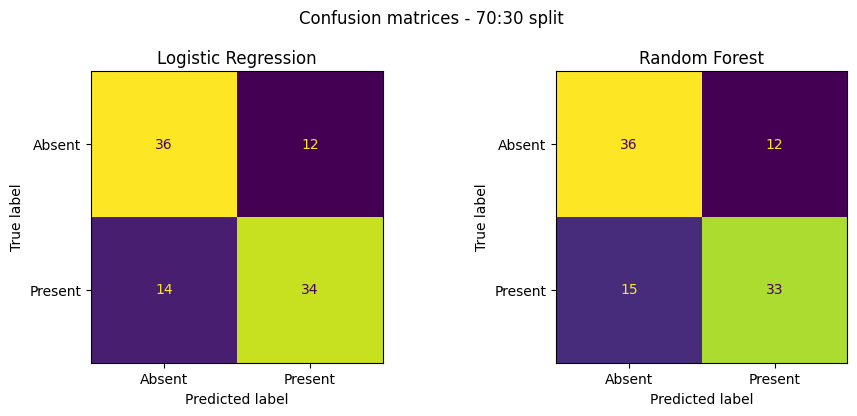


Logistic Regression: TN=36, FP=12, FN=14, TP=34
False negatives are disease-positive patients missed by the model; false positives are absent cases flagged as disease.
              precision    recall  f1-score   support

      Absent      0.720     0.750     0.735        48
     Present      0.739     0.708     0.723        48

    accuracy                          0.729        96
   macro avg      0.730     0.729     0.729        96
weighted avg      0.730     0.729     0.729        96


Random Forest: TN=36, FP=12, FN=15, TP=33
False negatives are disease-positive patients missed by the model; false positives are absent cases flagged as disease.
              precision    recall  f1-score   support

      Absent      0.706     0.750     0.727        48
     Present      0.733     0.688     0.710        48

    accuracy                          0.719        96
   macro avg      0.720     0.719     0.718        96
weighted avg      0.720     0.719     0.718        96



In [12]:
# 5.2 Confusion matrices and error analysis
fig, axes = plt.subplots(1,2,figsize=(9.5,4.2))
for ax,(name,(pred,prob)) in zip(axes,predictions70.items()):
    ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=['Absent','Present'],ax=ax,colorbar=False)
    ax.set_title(name)
plt.suptitle('Confusion matrices - 70:30 split')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'05_confusion_matrices_70_30.png',dpi=180,bbox_inches='tight')
plt.show()

for name,(pred,prob) in predictions70.items():
    tn,fp,fn,tp=confusion_matrix(y_test,pred).ravel()
    print(f'\n{name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}')
    print('False negatives are disease-positive patients missed by the model; false positives are absent cases flagged as disease.')
    print(classification_report(y_test,pred,target_names=['Absent','Present'],digits=3))


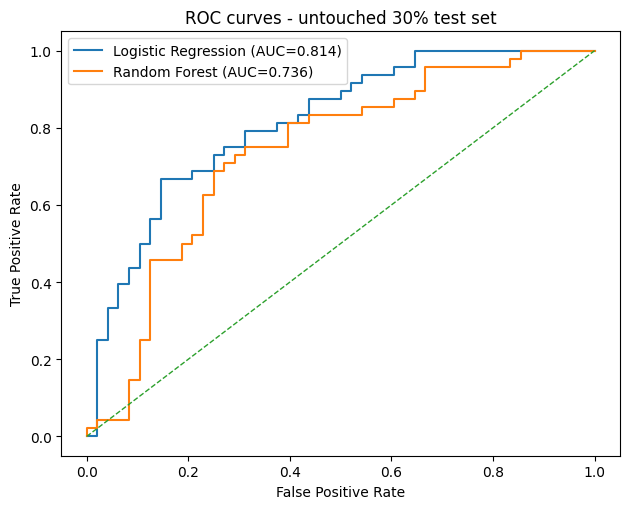

In [13]:
# 5.3 ROC curves
fig,ax=plt.subplots(figsize=(6.4,5.2))
for name,(pred,prob) in predictions70.items():
    fpr,tpr,_=roc_curve(y_test,prob)
    auc=roc_auc_score(y_test,prob)
    ax.plot(fpr,tpr,label=f'{name} (AUC={auc:.3f})')
ax.plot([0,1],[0,1],'--',linewidth=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC curves - untouched 30% test set')
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'06_roc_curves_70_30.png',dpi=180,bbox_inches='tight')
plt.show()


In [14]:
# 5.4 Robustness check: change to an 80:20 split and retune both models using the same CV strategy
X_train80, X_test80, y_train80, y_test80 = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

searches80={}
for name,pipe,grid in [
    ('Logistic Regression', log_pipe, log_grid),
    ('Random Forest', rf_pipe, rf_grid)
]:
    start=time.perf_counter()
    gs=GridSearchCV(pipe,grid,cv=cv,scoring='roc_auc',n_jobs=-1,refit=True)
    gs.fit(X_train80,y_train80)
    searches80[name]={'search':gs,'tuning_seconds':time.perf_counter()-start}

results80=[]
for name,obj in searches80.items():
    model=obj['search'].best_estimator_
    pred=model.predict(X_test80)
    prob=model.predict_proba(X_test80)[:,1]
    results80.append({'Model':name, **metric_row(y_test80,pred,prob),
                      'Tuning seconds':obj['tuning_seconds']})
results80=pd.DataFrame(results80).set_index('Model').sort_values('ROC-AUC',ascending=False)
print('80:20 test-set performance')
display(results80)
results80.to_csv(OUTPUT_DIR/'80_20_test_metrics.csv')

best80_name=results80.index[0]
print('Best under 70:30:',best70_name)
print('Best under 80:20:',best80_name)
print('Ranking preserved?',best70_name==best80_name)


80:20 test-set performance


,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Tuning seconds
Model,,,,,,,
Logistic Regression,0.6875,0.6875,0.7143,0.6250,0.6667,0.8164,0.3116
Random Forest,0.7344,0.7344,0.7586,0.6875,0.7213,0.7734,4.3492


Best under 70:30: Logistic Regression
Best under 80:20: Logistic Regression
Ranking preserved? True


70:30                                            \
                    Accuracy Balanced Accuracy Precision Recall     F1   
Model                                                                    
Logistic Regression   0.7292            0.7292    0.7391 0.7083 0.7234   
Random Forest         0.7188            0.7188    0.7333 0.6875 0.7097   

                               80:20                                     \
                    ROC-AUC Accuracy Balanced Accuracy Precision Recall   
Model                                                                     
Logistic Regression  0.8142   0.6875            0.6875    0.7143 0.6250   
Random Forest        0.7361   0.7344            0.7344    0.7586 0.6875   

                                    
                        F1 ROC-AUC  
Model                               
Logistic Regression 0.6667  0.8164  
Random Forest       0.7213  0.7734

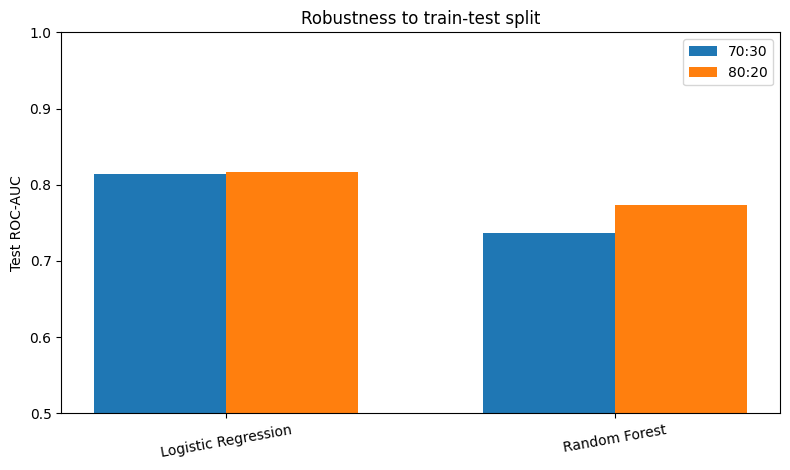

In [15]:
# 5.5 Direct split comparison
compare = pd.concat({
    '70:30': results70[['Accuracy','Balanced Accuracy','Precision','Recall','F1','ROC-AUC']],
    '80:20': results80[['Accuracy','Balanced Accuracy','Precision','Recall','F1','ROC-AUC']]
}, axis=1)
display(compare)
compare.to_csv(OUTPUT_DIR/'split_comparison.csv')

fig,ax=plt.subplots(figsize=(8,4.8))
labels=list(results70.index)
x=np.arange(len(labels)); w=.34
auc70=results70.loc[labels,'ROC-AUC']
auc80=results80.reindex(labels)['ROC-AUC']
ax.bar(x-w/2,auc70,width=w,label='70:30')
ax.bar(x+w/2,auc80,width=w,label='80:20')
ax.set_xticks(x); ax.set_xticklabels(labels,rotation=10)
ax.set_ylim(0.5,1.0); ax.set_ylabel('Test ROC-AUC')
ax.set_title('Robustness to train-test split')
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'07_split_robustness.png',dpi=180,bbox_inches='tight')
plt.show()


In [16]:
# 5.6 Feature evidence from the fitted models (useful for the EDA/recommendation discussion)
# Obtain transformed feature names from each best pipeline.
for name,obj in searches.items():
    pipe=obj['search'].best_estimator_
    prep=pipe.named_steps['preprocess']
    names=prep.get_feature_names_out()
    if name=='Logistic Regression':
        vals=pipe.named_steps['model'].coef_[0]
        imp=pd.DataFrame({'feature':names,'coefficient':vals,'abs_importance':np.abs(vals)})\
              .sort_values('abs_importance',ascending=False).head(15)
        print('\nTop Logistic Regression coefficients:')
    else:
        vals=pipe.named_steps['model'].feature_importances_
        imp=pd.DataFrame({'feature':names,'importance':vals,'abs_importance':vals})\
              .sort_values('abs_importance',ascending=False).head(15)
        print('\nTop Random Forest impurity importances:')
    display(imp)
    imp.to_csv(OUTPUT_DIR/f"feature_importance_{name.lower().replace(' ','_')}.csv",index=False)



Top Logistic Regression coefficients:


,feature,coefficient,abs_importance
0,num__Age,1.5045,1.5045
18,num__Glucose,-0.1364,0.1364
8,num__Total Body Fat Ratio (TBFR) (%),-0.0974,0.0974
5,num__Extracellular Water (ECW),0.0014,0.0014
1,num__Height,0.0000,0.0000
4,num__Total Body Water (TBW),0.0000,0.0000
3,num__Body Mass Index (BMI),0.0000,0.0000
6,num__Intracellular Water (ICW),0.0000,0.0000
7,num__Extracellular Fluid/Total Body Water (ECF...,0.0000,0.0000
9,num__Lean Mass (LM) (%),0.0000,0.0000



Top Random Forest impurity importances:


,feature,importance,abs_importance
0,num__Age,0.2907,0.2907
8,num__Total Body Fat Ratio (TBFR) (%),0.0519,0.0519
3,num__Body Mass Index (BMI),0.0341,0.0341
23,num__Aspartat Aminotransferaz (AST),0.0312,0.0312
29,num__Hemoglobin (HGB),0.0310,0.0310
18,num__Glucose,0.0282,0.0282
26,num__Creatinine,0.0271,0.0271
6,num__Intracellular Water (ICW),0.0250,0.0250
7,num__Extracellular Fluid/Total Body Water (ECF...,0.0242,0.0242
27,num__Glomerular Filtration Rate (GFR),0.0240,0.0240


In [17]:
# 5.7 Evidence-based recommendation from the actual results
best70 = results70.loc[best70_name]
other70_name = [n for n in results70.index if n != best70_name][0]
other70 = results70.loc[other70_name]

print('FINAL MODEL RECOMMENDATION')
print('-'*78)
print(f"Under the 70:30 split, {best70_name} achieved the highest test ROC-AUC ({best70['ROC-AUC']:.3f}) "
      f"with F1={best70['F1']:.3f} and recall={best70['Recall']:.3f}. "
      f"The comparison model, {other70_name}, had ROC-AUC={other70['ROC-AUC']:.3f}.")
print(f"Under the 80:20 split, {best80_name} still had the highest ROC-AUC. "
      f"The ROC-AUC ranking was {'stable' if best80_name==best70_name else 'not stable'} across splits.")
print('However, the 80:20 threshold-based accuracy and F1 values should also be inspected because they can rank the models differently.')
print('For deployment, interpretability, calibration, external validation, false-negative risk, privacy and clinical workflow must be considered.')


FINAL MODEL RECOMMENDATION
------------------------------------------------------------------------------
Under the 70:30 split, Logistic Regression achieved the highest test ROC-AUC (0.814) with F1=0.723 and recall=0.708. The comparison model, Random Forest, had ROC-AUC=0.736.
Under the 80:20 split, Logistic Regression still had the highest ROC-AUC. The ROC-AUC ranking was stable across splits.
However, the 80:20 threshold-based accuracy and F1 values should also be inspected because they can rank the models differently.
For deployment, interpretability, calibration, external validation, false-negative risk, privacy and clinical workflow must be considered.


## 6. Reflection on machine-learning model development (maximum 200 words)

The main challenge was making a fair comparison on a small clinical dataset without allowing test-set information to influence model selection. A stratified split preserved the class ratio, while five-fold cross-validation was used only on the training data for hyperparameter selection. A second challenge was handling mixed feature types without leakage. Continuous variables were imputed and standardised inside the pipeline, while categorical and ordinal-coded variables were imputed and one-hot encoded.

The results also demonstrated the trade-off between predictive performance and complexity. Logistic Regression was easier to interpret and showed a small train-validation ROC-AUC gap, whereas Random Forest achieved perfect training ROC-AUC but a lower validation score, indicating overfitting risk. The 80:20 experiment showed that Logistic Regression retained the best ROC-AUC, although Random Forest had better threshold-based accuracy and F1 on that particular test split. This illustrates why conclusions should not depend on one metric or one partition.

Future work should use larger external cohorts, nested cross-validation, probability calibration, clinically justified decision thresholds, fairness analysis, and prospective validation before any clinical deployment.


## Saved outputs

The notebook saves the main figures and CSV result tables to the `sit720_6_2c_outputs` folder. These outputs are used in the accompanying PDF report.


## References

1. UCI Machine Learning Repository, **Gallstone**, dataset ID 1150. The repository documents the 38 predictors, absence of missing values, and target coding 0 = gallstones present and 1 = absent.
2. I. Esen et al., “Early prediction of gallstone disease with a machine learning-based method from bioimpedance and laboratory data,” *Medicine*, 2024.
3. SIT720 Task 6.2C assessment brief supplied for this task.

## GenAI acknowledgement

ChatGPT was used to assist with planning the analysis, creating an initial code scaffold, debugging, checking coverage of the assessment brief, and editing the written explanations. The notebook was executed on the Gallstone dataset and the reported metrics and figures are generated by the code. The student is responsible for critically reviewing the analysis, understanding the modelling decisions, and ensuring the final submitted work complies with Deakin academic-integrity requirements.
